## Module 3: Computational Drug Discovery Project

Team Members: Reilly Hiner and Martina Ribera

## Project Goal:

We are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Our overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Our project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Obesity is defined as a chronic disease that occurs when excess body fat has a negative impact on an individual's health (Davis, n.d.). The extra weight has consequences including increased risk of heart disease, diabetes, and cancer as well as tiredness, joint pain, and difficulty performing physical activities (CDC, 2026). Medically, obesity can be divided into three categories defined by BMI (body mass index). Class 1 is individuals with a BMI between 30 and 35, Class 2 is a BMI between 35 and 40, and Class 3 or "morbid obesity" is any BMI above 40. Obesity is a common disease, impacting 2 in 5 United States Adults, or approximately 40% of the population. Additionally, obesity results in increased medical costs of over $1,861 per person and a total of over $173 billion annually (CDC, 2025). Current treatments for obesity consist mostly of lifestyle and dietary changes or expensive medical procedures, which may not be possible for everyone (Mayo Clinic, 2025). Other preexisting conditions may prevent the level of physical activity needed for weight loss, or the individual may not have the financial means and access to healthier options. For these reasons, improved treatments for obesity are in high demand to improve the livelihood of many Americans.

## Task 1: Fit a receptor binding model for Cavalitide:

Our colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). We now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor.

We must:

a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)


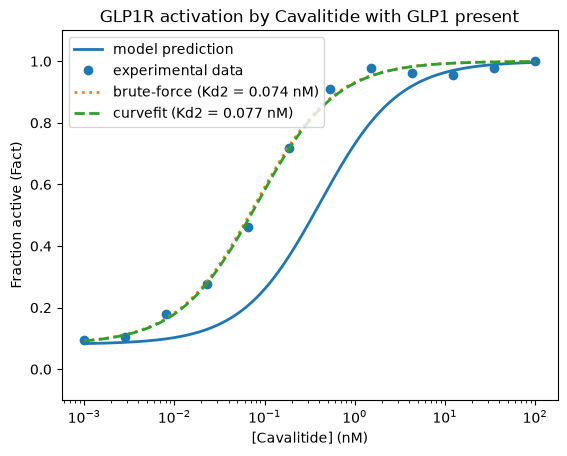

In [1]:
# fit_cavalitide_GLP1R.py

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # default 0.38 L2, Cavalitide (to fit)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")


# making the graphs
plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
                     label="model prediction")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
             label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.show()


Graph & Results Interpretation

The brute force optimization of Cavalitide estimated a dissociation constant (Kd) of 0.074 nM, while the curve fit estimated 0.077 nM. Both estimation methods produced very similar results, but the curve fit results better fit to the data, because it had a lower sum of squared errors (SSE) of 0.0052 while brute force optimization which had a SSE of 0.0054 . Compared to semaglutide's Kd of 0.38 nM, Cavalitide's Kd of ~0.077 is nearly 5 times lower. The graph also demonstrates that the fitted Cavalitide model very closely matches the experimental receptor activation data.

These results indicate that Cavalitide has a much higher model binding affinity for GLP1R than semaglutide, which also suggests that it can bind more effectively at lower concentrations. 

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

We are now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

Part 1

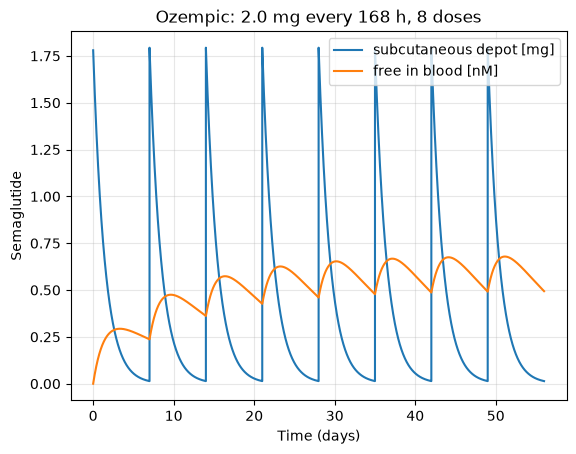

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Ozempic'
#drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size originally, now time interval for plotting

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))     ##STILL KEEP for new math# Euler steps per dosing interval 
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, [t_seg[0], t_seg[-1]], y, t_eval=t_seg) #given by vscode AI, this approximates using the new math method, which is more accurate than the Euler method
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


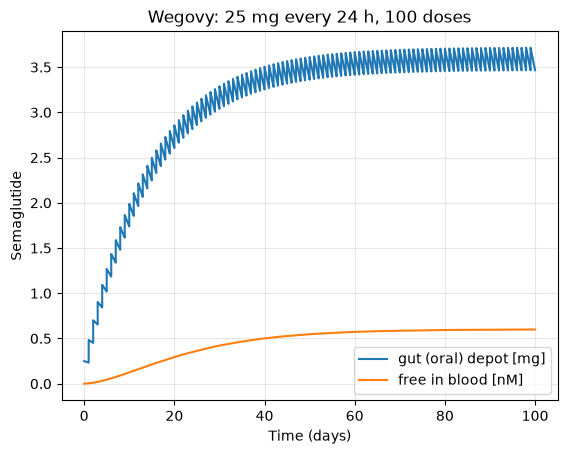

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size originally, now time interval for plotting

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))     ##STILL KEEP for new math# Euler steps per dosing interval 
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, [t_seg[0], t_seg[-1]], y, t_eval=t_seg) #given by vscode AI, this approximates using the new math method, which is more accurate than the Euler method
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Both Ozempic and Wegovy simluations were run using scipy.integrate.solve_ivp instead of Euler's method. Ozempic, which was administered as 2mg weekly injections, exhibited noticeable fluctuations in free blood concentration and reached a concentration of approximately 0.5-0.7 nM after 50 days. Wegovy, which was administered as a 25 mg daily pill, exhibited a smoother and more gradual increase in blood concentration, eventually approaching 0.54 nM after 100 days. The difference in concentration increase is due to administration method. Injections lead to instant spikes and gradual decreases in concentration, whereas pills lead to slow, gradual increase. 

Part 2.

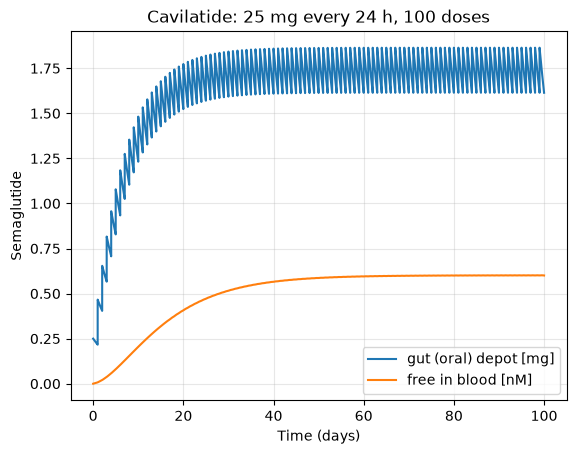

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
#drug = 'Wegovy'
drug = 'Cavilatide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavilatide':  dict(Favailable=0.01, #this is a pill so same dosage paramteres as wegovy assumed
                    ka=0.006,            # 1/h, absorption rate
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size originally, now time interval for plotting

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))     ##STILL KEEP for new math# Euler steps per dosing interval 
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, [t_seg[0], t_seg[-1]], y, t_eval=t_seg) #given by vscode AI, this approximates using the new math method, which is more accurate than the Euler method
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The Cavalitide simulation used an increased absorption rate of 0.006 1/h compared to Wegovy's 0.0029 1/h. Similar to Wegovy, the graph shows a gradual increase in free blood concentration, however here it stabilizes at approximately 0.6 nM after only 60 days. The higher absorption rate causes Cavilitide to leave the oral depot more quickly, which results in larger daily fluctuations in depot concentration and a faster initial increase in free blood concentration compared to Wegovy. 



Part 3.

Final free Blood Concentration: 0.5043224236622355


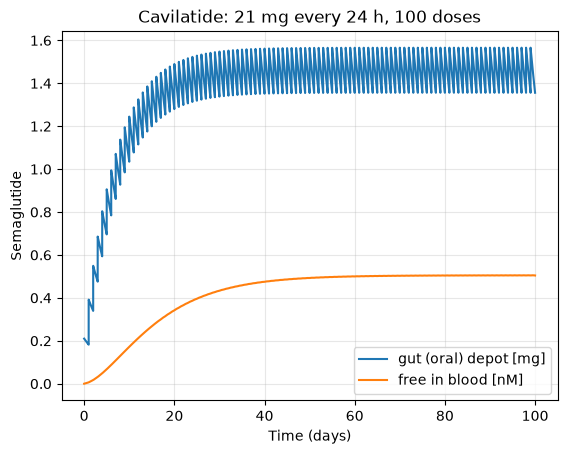

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
#drug = 'Wegovy'
drug = 'Cavilatide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavilatide':  dict(Favailable=0.01, #this is a pill so same dosage paramteres as wegovy assumed
                    ka=0.006,            # 1/h, absorption rate
                    D=21,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size originally, now time interval for plotting

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))     ##STILL KEEP for new math# Euler steps per dosing interval 
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, [t_seg[0], t_seg[-1]], y, t_eval=t_seg) #given by vscode AI, this approximates using the new math method, which is more accurate than the Euler method
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)
print("Final free Blood Concentration:", Ffree * Cc[-1])

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Results & Interpretation

In order to acheive the desired steady state of 0.5 nM, we changed the dosing amount to 21 mg, while keeping all other parameters the same. This resulted in a steady state of 0.504 nM, which is very close to the desired concentration and deemed acceptable. 

An alternative that we considered was decreasing dosage time and amount to 10.5 mg every 12 hours, and keeping all other parameters the same. This resulted in the same steady state concentration of 0.504 nM. This simulation exhibited much smaller fluctuations in depot concentration, which would be beneficial because it would lead to more stabilized blood concentration in between dosages. However, it was concluded that the decrease in depot concentration fluctuation was not beneficial enough to justify increasing the dosage frequency, which would have been more inconvenient for the patient and could reduce medication adherence.

Inconvenience to the patient and consequent reduction in medical adherence were the main reasons that time intervals other than 24 and 12 hours were not considered. 

For both simulations, number of doses was adjusted as necessary to cover 100 days, in order to clearly calculate steady state final concentration.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


Part 1


Final free Blood Concentration: 0.5043224236622356
Final free blood concentration: 0.5043224236622356 nM
Final fraction of active GLP1 receptors: 0.8690735686015927
Final receptor activation: 86.90735686015927 %


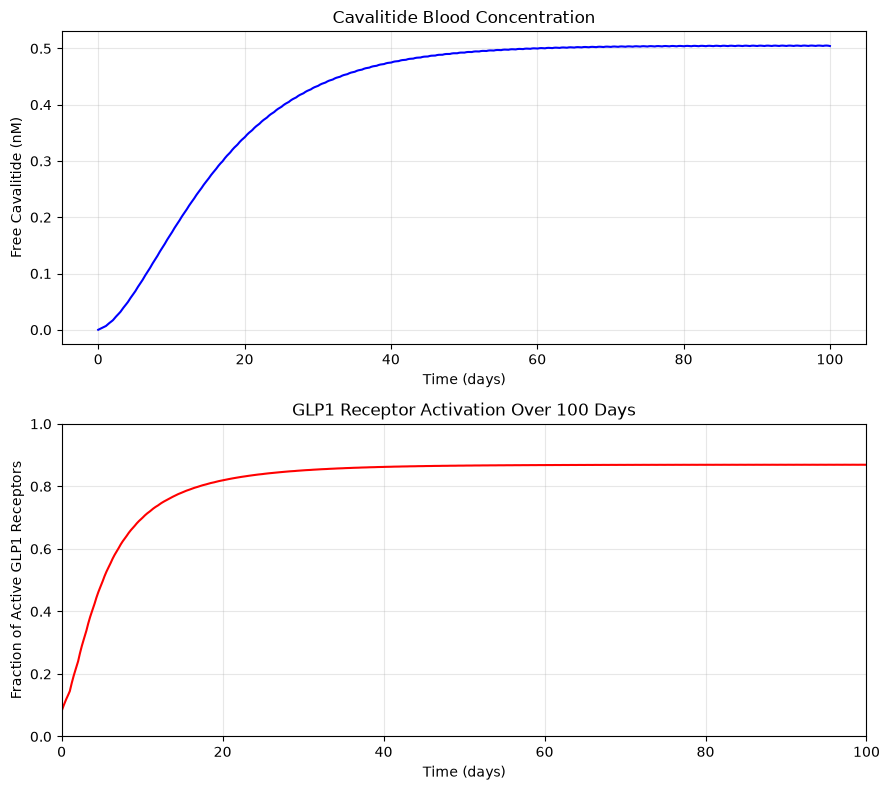

In [3]:
#CavalitidePKPD.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Optimized binding parameters from Task 1
Kd1 = 0.17       # GLP1 Kd (nM)
Kd2 = 0.077      # Optimized Cavalitide Kd (nM)
L1 = 0.015       # Fasting GLP1 concentration (nM)

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Cavilatide'

# product-specific parameters
products = {
    'Cavilatide':  dict(Favailable=0.01, #this is a pill so same dosage paramteres as wegovy assumed
                    ka=0.006,            # 1/h, absorption rate
                    D=21,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size originally, now time interval for plotting


def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))     ##STILL KEEP for new math# Euler steps per dosing interval 
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, [t_seg[0], t_seg[-1]], y, t_eval=t_seg) #given by vscode AI, this approximates using the new math method, which is more accurate than the Euler method
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)
print("Final free Blood Concentration:", Ffree * Cc[-1])

Cc_free = Ffree * Cc

fraction_active = Fact(L1, Cc_free, Kd1, Kd2)


# ===== Results =====

print("Final free blood concentration:",
      Cc_free[-1], "nM")

print("Final fraction of active GLP1 receptors:",
      fraction_active[-1])

print("Final receptor activation:",
      fraction_active[-1] * 100, "%")


# ===== Plot PK and PD results =====

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8))

# PK plot
ax1.plot(t / 24, Cc_free, color='blue')
ax1.set_xlabel("Time (days)")
ax1.set_ylabel("Free Cavalitide (nM)")
ax1.set_title("Cavalitide Blood Concentration")
ax1.grid(alpha=0.3)

# PD plot
ax2.plot(t / 24, fraction_active, color='red')
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("Fraction of Active GLP1 Receptors")
ax2.set_title("GLP1 Receptor Activation Over 100 Days")
ax2.set_ylim(0, 1)
ax2.set_xlim(0, 100)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The block above is the combined data from parts 1 and 2. It demonstrates the ligand-receptor model with the closest approximation of Kd from part 1, 0.077 nM (fitted approach). In the code, this approximation was used as the value of Kd2, and the number of dosages was set as 100, to display the trend over 100 days. We also used the "better" dosage information from part two; 21mg, once daily, in this comparison. With this data, the final receptor activation was 86.907% when cavalitide concentration steadied at approximately 0.5nM.


Part 2

The following code is the same as the previous, but with one significant change. To determine the impacts on receptor activation, we switched the dosage to 10.5mg, twice daily. To account for 100 days, 200 doses were plotted. 

Final free Blood Concentration: 0.5047446470494864
Final free blood concentration: 0.5047446470494864 nM
Final fraction of active GLP1 receptors: 0.869167496486486
Final receptor activation: 86.91674964864859 %


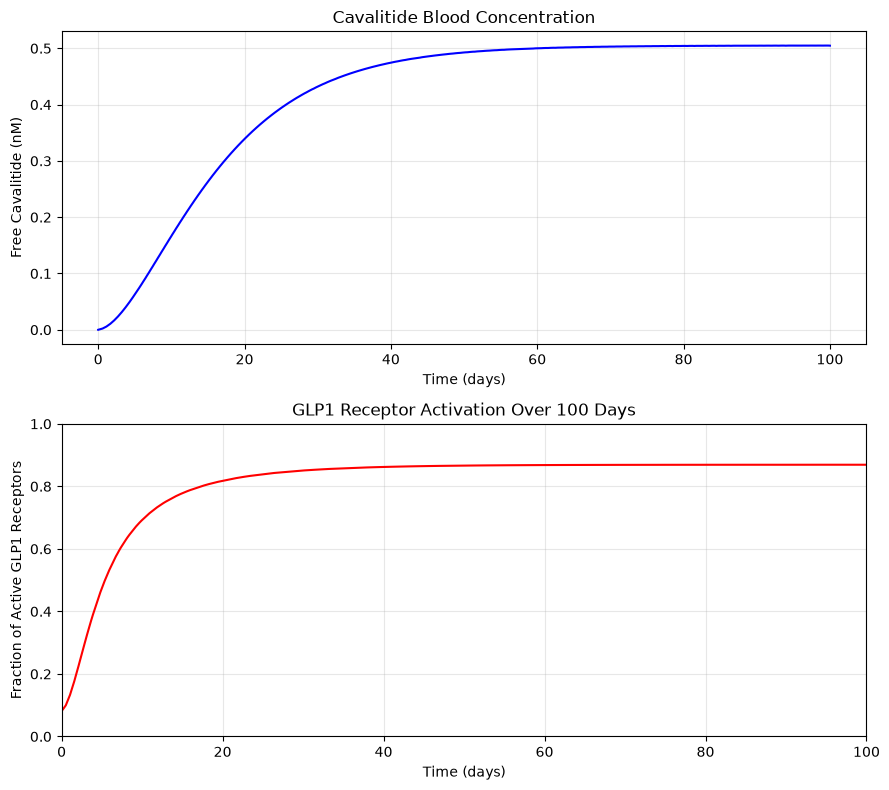

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Optimized binding parameters from Task 1
Kd1 = 0.17       # GLP1 Kd (nM)
Kd2 = 0.077      # Optimized Cavalitide Kd (nM)
L1 = 0.015       # Fasting GLP1 concentration (nM)

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Cavilatide'

# product-specific parameters
products = {
    'Cavilatide':  dict(Favailable=0.01, #this is a pill so same dosage paramteres as wegovy assumed
                    ka=0.006,            # 1/h, absorption rate
                    D=10.5,               # mg
                    interval=12,       # h between doses (daily)
                    n_doses=200,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size originally, now time interval for plotting


def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))     ##STILL KEEP for new math# Euler steps per dosing interval 
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, [t_seg[0], t_seg[-1]], y, t_eval=t_seg) #given by vscode AI, this approximates using the new math method, which is more accurate than the Euler method
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)
print("Final free Blood Concentration:", Ffree * Cc[-1])

Cc_free = Ffree * Cc

fraction_active = Fact(L1, Cc_free, Kd1, Kd2)


# ===== Results =====

print("Final free blood concentration:",
      Cc_free[-1], "nM")

print("Final fraction of active GLP1 receptors:",
      fraction_active[-1])

print("Final receptor activation:",
      fraction_active[-1] * 100, "%")


# ===== Plot PK and PD results =====

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8))

# PK plot
ax1.plot(t / 24, Cc_free, color='blue')
ax1.set_xlabel("Time (days)")
ax1.set_ylabel("Free Cavalitide (nM)")
ax1.set_title("Cavalitide Blood Concentration")
ax1.grid(alpha=0.3)

# PD plot
ax2.plot(t / 24, fraction_active, color='red')
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("Fraction of Active GLP1 Receptors")
ax2.set_title("GLP1 Receptor Activation Over 100 Days")
ax2.set_ylim(0, 1)
ax2.set_xlim(0, 100)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

With this adjustment in dosage, there was only a slight increase in the fraction of activated GLP1 receptors. Receptor activation increased by approximately 0.01 percentage points, resulting in a final activation of 86.917%. Given the minimal improvement, this dosage adjustment is unlikely to provide any significant additional clinical benefit. Although the dosage could potentially be further optimized to achieve the highest possible GLP1 receptor activation, the resulting percentage would likely remain close to the approximately 87% activation observed with our original experimental parameters. Further adjustments to the dosage or time between doses may be possible; however, these changes could introduce unnecessary complications in manufacturing, such as the need for atypical dosage amounts and increased sensitivity to measurement or production errors. Adjustments may also result in further inconvenience to the patient, who would have to use the drug more frequently.

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*

ChatGPT was used throughout this project to help explain Python code, troubleshoot errors, and organize our computational analysis. Specifically, AI helped us understand how to incorporate the change from eulers to integrate.solve_IVP. AI also assisted with interpreting results. Additionally, AI was used as a supplementary research tool to help us understand GLP1 kinetics and identify any relevant scientific literature. 

## GitHub Repository Link:
https://github.com/martina-ribera/CompBME_Module3

## References:

CDC. (2025, March 25). Adult Obesity Facts. Obesity. https://www.cdc.gov/obesity/adult-obesity-facts/index.html 

CDC. (2026, July 9). Consequences of Obesity. Obesity. https://www.cdc.gov/obesity/php/about/consequences.html 

Davis, S. (n.d.). Obesity: Symptoms, Causes, Treatment. WebMD. Retrieved November 16, 2026, from https://www.webmd.com/obesity/what-obesity-is 

Mayo Clinic. (2025). Obesity—Diagnosis and treatment. Mayo Clinic. https://www.mayoclinic.org/diseases-conditions/obesity/diagnosis-treatment/drc-20375749 


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*